# Reduced feature importance figure

Two-panel feature importance figure, derived from the same processed tables as the per-model figures of the `lur-results` notebook:

* a selection/coefficient heatmap of every predictor--scale combination (`lur-importance-heatmap.pdf`), and
* beeswarms of the GAM term contributions and RF SHAP values of the headline predictors (`lur-importance-headline.pdf`).

In [1]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from zurich_uhi_lur import plot_utils

plot_utils.set_style()

In [2]:
# input data paths
dst_importance_filepath = "../data/processed/lur-importance.csv"
dst_shap_filepath = "../data/processed/lur-shap.csv"

# output figures
dst_importance_heatmap_filepath = "../reports/figures/lur-importance-heatmap.pdf"
dst_importance_headline_filepath = "../reports/figures/lur-importance-headline.pdf"

# experiment settings (must match lur-model)
fracs = [0, 0.33, 0.66, 1]
n_reps = 5

# number of predictors shown in the headline beeswarm figure (see the headline
# beeswarms section for the selection criterion)
n_headline_features = 5

In [3]:
# Parameters
dst_importance_filepath = "data/processed/lur-importance.csv"
dst_shap_filepath = "data/processed/lur-shap.csv"
dst_importance_heatmap_filepath = "reports/figures/lur-importance-heatmap.pdf"
dst_importance_headline_filepath = "reports/figures/lur-importance-headline.pdf"


## Load results

In [4]:
importance_df = pd.read_csv(dst_importance_filepath)
shap_df = pd.read_csv(dst_shap_filepath)

print(f"Loaded {len(importance_df)} importance rows, {len(shap_df)} shap rows")

Loaded 144 importance rows, 21502 shap rows


In [5]:
# feature groups, in the same order as the six-panel figure of `lur-results` so that
# both figures can be read side by side
multi_scale_groups = [
    (
        "Building volume",
        [
            "building_volume_sum_100",
            "building_volume_sum_250",
            "building_volume_sum_500",
        ],
    ),
    ("Tree cover", ["tree_sum_100", "tree_sum_250", "tree_sum_500"]),
    ("Northness", ["aspect_northness_250", "aspect_northness_500"]),
    ("Slope", ["slope_mean_250", "slope_mean_500"]),
    ("TPI", ["topographic_position_index_250", "topographic_position_index_500"]),
]
single_scale_groups = [
    ("Elevation", ["elevation_0"]),
    ("Lake distance", ["lake_distance_0"]),
]
frac_order = list(fracs)

# one row per predictor-scale combination, with its label, plus the row index at which
# each predictor group ends (to draw the group separators)
feature_rows = []
group_bounds = []
for group_label, group_features in multi_scale_groups:
    for feature in group_features:
        feature_rows.append((feature, f"{group_label} {feature.rsplit('_', 1)[-1]} m"))
    group_bounds.append(len(feature_rows))
for group_label, group_features in single_scale_groups:
    feature_rows.append((group_features[0], group_label))
    group_bounds.append(len(feature_rows))
# the last bound is the figure edge, no separator needed there
group_bounds = group_bounds[:-1]

feature_order = [feature for feature, _ in feature_rows]
row_labels = [label for _, label in feature_rows]
frac_labels = [f"{frac:g}" for frac in frac_order]

## Selection/coefficient heatmap

**Figure: mean standardized MLR coefficient and selection frequency per predictor and LCS fraction** (`lur-importance-heatmap.pdf`).

A feature is absent from `importance_df` for a given repetition exactly when the
selection step did not retain it, so the selection frequency (in how many of the
`n_reps` repetitions a feature entered the model) is the count of rows per
feature and fraction. The selection step runs before the regression and is shared
by MLR, GAM and RF, so this panel describes the station sample rather than a
single model.

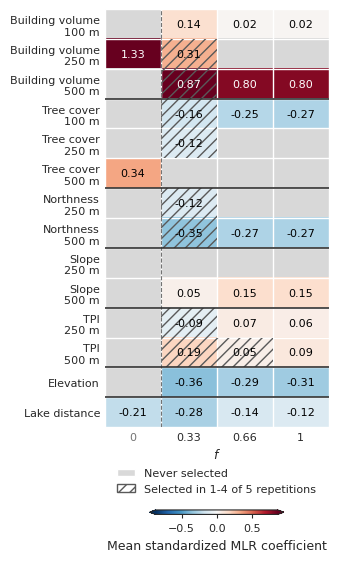

In [6]:
# mean standardized coefficient and selection frequency per predictor and fraction
mlr_df = importance_df.query("model == 'MLR'")
mean_df = mlr_df.pivot_table(
    index="feature", columns="frac", values="value", aggfunc="mean"
).reindex(index=feature_order, columns=frac_order)
sel_freq_df = (
    mlr_df.pivot_table(index="feature", columns="frac", values="value", aggfunc="count")
    .reindex(index=feature_order, columns=frac_order)
    .fillna(0)
    / n_reps
)

# ACHTUNG: the degenerate four-station fit puts its dominant coefficient above any f>0
# coefficient, so the color scale is set from the f>0 cells and the f=0 cells that
# exceed it saturate - the annotations still give their exact values
mean_arr = mean_df.to_numpy()
vmax = np.nanmax(np.abs(mean_arr[:, [i for i, f in enumerate(frac_order) if f > 0]]))

NOT_SELECTED_COLOR = "0.85"
# both panels of the article figure are drawn at their printed widths (0.473 and 0.507
# of the widened text block, minus the box reserved for the panel label) and share this
# printed height, so that they line up
IMPORTANCE_HEIGHT = 5.5  # in
HEATMAP_FIGSIZE = (
    0.473 * plot_utils.WIDE_TEXT_WIDTH - plot_utils.SUBFIGURE_LABEL_WIDTH,
    IMPORTANCE_HEIGHT,
)
LABEL_FONTSIZE = plot_utils.FONT_SIZE
TICK_FONTSIZE = plot_utils.SMALL_FONT_SIZE
ANNOT_FONTSIZE = plot_utils.SMALL_FONT_SIZE

cmap = plt.get_cmap("RdBu_r").copy()
cmap.set_bad(NOT_SELECTED_COLOR)
norm = plt.Normalize(vmin=-vmax, vmax=vmax)

fig, ax = plt.subplots(figsize=HEATMAP_FIGSIZE, layout="constrained")
im = ax.imshow(np.ma.masked_invalid(mean_arr), cmap=cmap, norm=norm, aspect="auto")

for row_idx in range(len(feature_order)):
    for col_idx in range(len(frac_order)):
        value = mean_arr[row_idx, col_idx]
        if np.isnan(value):
            continue
        # hatch the cells that were not selected in every repetition
        sel_freq = sel_freq_df.iloc[row_idx, col_idx]
        if sel_freq < 1:
            ax.add_patch(
                mpl.patches.Rectangle(
                    (col_idx - 0.5, row_idx - 0.5),
                    1,
                    1,
                    fill=False,
                    hatch="///",
                    edgecolor="0.35",
                    linewidth=0,
                )
            )
        # white text on the saturated cells, black elsewhere
        ax.text(
            col_idx,
            row_idx,
            f"{value:.2f}",
            ha="center",
            va="center",
            fontsize=ANNOT_FONTSIZE,
            color="white" if abs(value) > 0.6 * vmax else "black",
        )

ax.set_xticks(range(len(frac_order)), frac_labels)
# two-line row labels (predictor over buffer scale), so that the cells keep room for
# their annotations at the printed size
two_line_labels = [
    " ".join(label.split(" ")[:-2]) + "\n" + " ".join(label.split(" ")[-2:])
    if label.endswith(" m")
    else label
    for label in row_labels
]
ax.set_yticks(range(len(feature_order)), two_line_labels)
ax.set_xlabel("$f$", fontsize=LABEL_FONTSIZE)
# de-emphasize f=0, where only four stations (hence at most three predictors) are used
ax.get_xticklabels()[frac_order.index(0)].set_color("0.45")
ax.axvline(0.5, color="0.45", linestyle="--", linewidth=0.8)

# cell separators
ax.set_xticks(np.arange(len(frac_order) + 1) - 0.5, minor=True)
ax.set_yticks(np.arange(len(feature_order) + 1) - 0.5, minor=True)
ax.grid(which="minor", color="white", linewidth=1)
ax.tick_params(which="minor", length=0)
ax.tick_params(which="major", length=0, labelsize=TICK_FONTSIZE)
for bound in group_bounds:
    ax.axhline(bound - 0.5, color="0.2", linewidth=1.2)
for spine in ax.spines.values():
    spine.set_visible(False)

# the legend and the colorbar are stacked below the panel, matching the headline figure.
# ACHTUNG: the colorbar pad is measured from the axes, not from the legend, so it has to
# clear the legend by a small margin
ax.legend(
    handles=[
        mpl.patches.Patch(facecolor=NOT_SELECTED_COLOR, label="Never selected"),
        mpl.patches.Patch(
            facecolor="white",
            edgecolor="0.35",
            hatch="///",
            label=f"Selected in 1-{n_reps - 1} of {n_reps} repetitions",
        ),
    ],
    loc="upper center",
    bbox_to_anchor=(0.5, -0.075),
    ncol=1,
    frameon=False,
    fontsize=ANNOT_FONTSIZE,
    handlelength=1.6,
)

cbar = fig.colorbar(
    im,
    ax=ax,
    orientation="horizontal",
    shrink=0.6,
    aspect=30,
    extend="both",
    pad=0.022,
)
cbar.set_label("Mean standardized MLR coefficient", fontsize=LABEL_FONTSIZE)
cbar.ax.tick_params(labelsize=TICK_FONTSIZE)

fig.savefig(dst_importance_heatmap_filepath)

## Headline beeswarms

**Figure: GAM term contributions and RF SHAP values of the headline predictors across LCS fractions** (`lur-importance-headline.pdf`).

GAM term contributions and RF SHAP values for the headline predictors only, i.e.,
the `n_headline_features` predictor--scale combinations with the largest mean
standardized MLR coefficient magnitude across the fractions at which LCS stations are
present ($f > 0$). Averaging over those fractions rather than taking $f = 1$ alone
keeps the rows on the predictors that carry the fit throughout the densification:
building volume at 500 m, elevation, northness, tree cover at 100 m and distance to
the lake. At $f=0$ the models are fit on the four AWS stations, where the selection
step retains at most three predictors and each beeswarm would hold four points, so
that column is shaded and is annotated as "not selected" wherever the predictor did
not enter; the predictor that dominates the four-station fit is read from the heatmap
instead.

In [7]:
# headline predictors: the largest mean |coefficient| across the fractions at which LCS
# stations are present, displayed in the same order as the heatmap rows. Averaging over
# f > 0 rather than taking f = 1 alone keeps the rows on the predictors that carry the
# fit throughout the densification. The f = 0 fit is degenerate (four stations, hence at
# most three predictors and four points per beeswarm), so its dominant predictor is read
# from the heatmap rather than given a row here
positive_fracs = [frac for frac in frac_order if frac > 0]
headline_ranking = (
    mean_df[positive_fracs].abs().mean(axis="columns").sort_values(ascending=False)
)
headline_features = [
    feature
    for feature in feature_order
    if feature in headline_ranking.index[:n_headline_features]
]
print(headline_ranking.head(n_headline_features + 2).round(3))

feature
building_volume_sum_500    0.822
elevation_0                0.320
building_volume_sum_250    0.307
aspect_northness_500       0.297
tree_sum_100               0.226
lake_distance_0            0.180
aspect_northness_250       0.118
dtype: float64


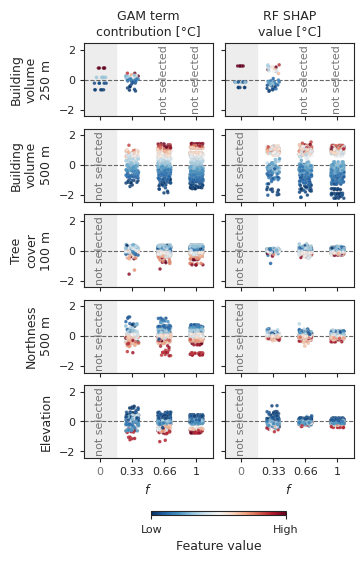

In [8]:
# drawn at its printed width, sharing the printed height of the heatmap panel
HEADLINE_FIGSIZE = (
    0.507 * plot_utils.WIDE_TEXT_WIDTH - plot_utils.SUBFIGURE_LABEL_WIDTH,
    IMPORTANCE_HEIGHT,
)
FZERO_COLOR = "0.93"
JITTER = 0.2
LABEL_FONTSIZE = plot_utils.FONT_SIZE
TICK_FONTSIZE = plot_utils.SMALL_FONT_SIZE
ANNOT_FONTSIZE = plot_utils.SMALL_FONT_SIZE

headline_labels = dict(
    zip(
        [feature for feature, _ in feature_rows],
        [label for _, label in feature_rows],
    )
)
model_labels = {
    "GAM": "GAM term\ncontribution [°C]",
    "RF": "RF SHAP\nvalue [°C]",
}

plot_df = shap_df[shap_df["feature"].isin(headline_features)]

# shared, symmetric y limits across the panels
max_abs = plot_df["shap_value"].abs().max()
ylim = (-1.1 * max_abs, 1.1 * max_abs)

# per-feature value range for consistent beeswarm coloring across fracs and models,
# computed on the full table so that colors match the six-panel figure
feat_vranges = (
    shap_df.groupby("feature")["feature_value"]
    .agg(vmin="min", vmax="max")
    .to_dict("index")
)

fig, axes = plt.subplots(
    len(headline_features),
    len(model_labels),
    figsize=HEADLINE_FIGSIZE,
    sharex=True,
    sharey=True,
    squeeze=False,
    layout="constrained",
)
rng = np.random.default_rng(42)

for row_idx, feature in enumerate(headline_features):
    for col_idx, model_name in enumerate(model_labels):
        ax = axes[row_idx, col_idx]
        # shade the f=0 column, fit on the four AWS stations only
        ax.axvspan(-0.5, 0.5, color=FZERO_COLOR, zorder=0)
        ax.axhline(0, color="0.4", linestyle="--", linewidth=0.8, zorder=1)

        feature_df = plot_df.query("model == @model_name and feature == @feature")
        vrange = feat_vranges[feature]
        color_norm = plt.Normalize(vmin=vrange["vmin"], vmax=vrange["vmax"])
        for frac_idx, frac in enumerate(frac_order):
            frac_df = feature_df[np.isclose(feature_df["frac"], frac)]
            if frac_df.empty:
                # the predictor did not enter the model at this fraction
                ax.text(
                    frac_idx,
                    0,
                    "not selected",
                    ha="center",
                    va="center",
                    fontsize=ANNOT_FONTSIZE,
                    color="0.45",
                    rotation=90,
                )
                continue
            ax.scatter(
                frac_idx + rng.uniform(-JITTER, JITTER, len(frac_df)),
                frac_df["shap_value"].to_numpy(),
                c=plt.cm.RdBu_r(color_norm(frac_df["feature_value"].to_numpy())),
                s=6,
                alpha=0.85,
                # thin edges so that mid-range (near-white) feature values stay visible
                edgecolors="0.7",
                linewidths=0.1,
                zorder=2,
            )

        ax.set_ylim(ylim)
        ax.set_xlim(-0.5, len(frac_order) - 0.5)
        ax.set_xticks(range(len(frac_order)), frac_labels)
        ax.tick_params(labelsize=TICK_FONTSIZE)
        if row_idx == 0:
            ax.set_title(model_labels[model_name], fontsize=LABEL_FONTSIZE)
        if row_idx == len(headline_features) - 1:
            # x tick labels only exist on the bottom row (shared x axis)
            ax.set_xlabel("$f$", fontsize=LABEL_FONTSIZE)
            ax.get_xticklabels()[frac_order.index(0)].set_color("0.45")
        if col_idx == 0:
            # one word per line (keeping the buffer scale together), so that the
            # rotated labels of adjacent rows do not collide at the printed size
            words = headline_labels[feature].split(" ")
            if headline_labels[feature].endswith(" m"):
                words = words[:-2] + [" ".join(words[-2:])]
            ax.set_ylabel("\n".join(words), fontsize=LABEL_FONTSIZE)

sm = plt.cm.ScalarMappable(cmap="RdBu_r", norm=plt.Normalize(0, 1))
sm.set_array([])
cbar = fig.colorbar(
    sm, ax=axes, orientation="horizontal", shrink=0.5, aspect=30, pad=0.03
)
cbar.set_ticks([0, 1], labels=["Low", "High"])
cbar.ax.tick_params(labelsize=TICK_FONTSIZE)
cbar.set_label("Feature value", fontsize=LABEL_FONTSIZE)

fig.savefig(dst_importance_headline_filepath)